# Phase 2 (v3): one shared, decentralized policy, one goal slot per drone

One small MLP, copied onto every drone, maps what that drone sees to an acceleration. Training backpropagates the formation loss through the simulator. **v3**: every shape is laid out as exactly one goal slot per drone (M = N, `swarm/layout.py`), the swarm size is drawn from 8-96 every batch, training includes random letter/digit strings, and the policy is scored by one-to-one matching of drones to slots.

The math is in `docs/walkthrough/phase2.html`; v2 → v3 changes are in `docs/phases_explained.txt`. All code is imported from `swarm/`. Each run has a name (`EXPERIMENT`, or the environment variable of the same name) and writes under the tag `phase2_v3_<name>`, so v2 results are never overwritten; `notebooks/phase2_compare.ipynb` compares runs. Set `TRAIN = False` to reuse a finished run.

| Section | What it shows |
|---|---|
| 1 | Setup |
| 2 | The data: sizes, shape families, held-out strings, the fixed benchmark |
| 3 | What one drone sees |
| 4 | Training, with live curves |
| 5 | Results per swarm size: slots filled, slot error, steps to form |
| 6 | Every size and shape, plus GIFs |
| 7 | Held-out shapes, strings and words |
| 8 | Beyond the training range: words with 128 drones |
| 9 | Policy vs the Phase 1 fixed plan |

## 1. Setup

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import os, sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:   # find the repo root
    ROOT = ROOT.parent
os.chdir(ROOT)                              # so configs/, data/, runs/ and results/ resolve
sys.path.insert(0, str(ROOT))               # so `import swarm` works

import json
import shutil
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, clear_output, display

from swarm import viz
from swarm.config import load_config, set_overrides
from swarm.dataset import (BENCH_DIR, BENCH_N, BENCH_SEED, HELDOUT_FAMILIES, HELDOUT_STRING_SEED, HELDOUT_STRINGS,
                           N_RANGE, TRAIN_FAMILIES, WORDS, build_benchmark, load_cell, text_scene)
from swarm.losses import chamfer
from swarm.metrics import FORM_THRESHOLD
from swarm.observations import _knn_idx, goal_occupancy, knn_offsets
from swarm.plan import optimize_plan
from swarm.policy import SharedMLP, policy_from_config
from swarm.sim import rollout, rollout_closed_loop
from swarm.train import evaluate_benchmark, evaluate_cell, overall, train

cfg = load_config("configs/default.yaml")

VERSION = "v3"
EXPERIMENT = os.environ.get("EXPERIMENT", "spacing")   # name of this run
EXPERIMENTS = {               # settings that differ from configs/default.yaml
    "baseline": {},                                   # shape + collision + effort
    "spacing": {"loss.w_spacing": 1.0},               # + repulsion toward even spacing (PU-Net-style)
}
set_overrides(cfg, EXPERIMENTS[EXPERIMENT])
TRAIN = os.environ.get("TRAIN", "1") == "1"   # False: reuse runs/<TAG>/best.pt instead of training
REBUILD_BENCHMARK = False                     # True: regenerate data/benchmark_v3 (about 5 minutes)
TAG = f"phase2_{VERSION}_{EXPERIMENT}"
RUN = Path(f"runs/{TAG}")
GIFS, FIGS = Path("results/gifs"), Path("results/figures")
print(f"{TAG}: {EXPERIMENTS[EXPERIMENT] or 'default settings'}")
print("parameters:", sum(p.numel() for p in policy_from_config(cfg).parameters()))

phase2_v3_spacing: {'loss.w_spacing': 1.0}
parameters: 6850


## 2. The data

Every training batch draws a swarm size N uniformly from 8 to 96, then 32 scenes with **N drones and N goal slots**. A slot sits at every stroke end, corner and junction (*anchors*), the rest are spread evenly. A scene passes the **feature-size rule** (parts of the shape far apart along the strokes must be at least one drone spacing apart in space); text that fails it is redrawn, so only readable strings are used. Each scene's collision distance is **d_min = 0.4 × drone spacing** (outline length ÷ N).

Text is Hershey Simplex, uppercase A-Z and 0-9. Training text: 1-2 random letters, or 1-4 random letters/digits. **Held out** (never generated in training): star, heart, spiral, the words HI, UMD, LOVE, FIRE, MARRY ME, and 12 fixed strings drawn with seed 838.

The fixed **benchmark** (`data/benchmark_v3/`, seed 2026) holds 4 scenes per family per size N ∈ {8, 16, 24, 32, 48, 64, 96}, each with its **per-scene optimum** (the Phase 1 method on that scene, same collision penalty). Every run and every Phase 3 baseline is scored on exactly these scenes.

In [2]:
if REBUILD_BENCHMARK or not Path(BENCH_DIR, "index.json").exists():
    build_benchmark(cfg)
index = json.loads(Path(BENCH_DIR, "index.json").read_text())
print(f"training sizes N = {N_RANGE[0]}-{N_RANGE[1]}; benchmark sizes {BENCH_N}; seeds: benchmark {BENCH_SEED}, "
      f"held-out strings {HELDOUT_STRING_SEED}")
print("training families:", TRAIN_FAMILIES)
print("held-out families:", HELDOUT_FAMILIES)
print("held-out words:", [w.replace(chr(10), " ") for w in WORDS], "  held-out strings:", HELDOUT_STRINGS, "\n")
print(f"{'N':>4s}{'split':>9s}{'seed':>6s}{'scenes':>8s}{'optimum: filled':>17s}{'slot err':>10s}  skipped / texts")
for r in index:
    print(f"{r['n']:4d}{r['split']:>9s}{r['seed']:6d}{r['scenes']:8d}{100 * r['oracle_filled']:16.0f}%{r['oracle_slot_error']:10.2f}"
          f"  {', '.join(r['skipped']) or '-'} / {' '.join(t.replace(chr(10), ' ') for t in r['texts'])}")

training sizes N = 8-96; benchmark sizes [8, 16, 24, 32, 48, 64, 96]; seeds: benchmark 2026, held-out strings 838
training families: ['circle', 'square', 'line', 'triangle', 'pentagon', 'random_polygon', 'random_polyline', 'letters', 'random_string']
held-out families: ['star', 'heart', 'spiral', 'word', 'heldout_string']
held-out words: ['HI', 'UMD', 'LOVE', 'FIRE', 'MARRY ME']   held-out strings: ['8', 'A', '63', '22', 'NY4', 'ODP', 'PH0', '0TO', '6F2L', 'G', 'CS', 'W'] 

   N    split  seed  scenes  optimum: filled  slot err  skipped / texts
   8    train  2026      36              85%      0.27  - / 7 B J L O P V X
   8  heldout  2027       8              81%      0.23  star, spiral, word / A W
  16    train  2126      36              83%      0.38  - / B D H KG M N Y
  16  heldout  2127      16              81%      0.37  spiral / A G HI
  24    train  2226      36              77%      0.73  - / 19 3 7Q1 D IY J L7 OD
  24  heldout  2227      20              80%      0.44  - / 63 

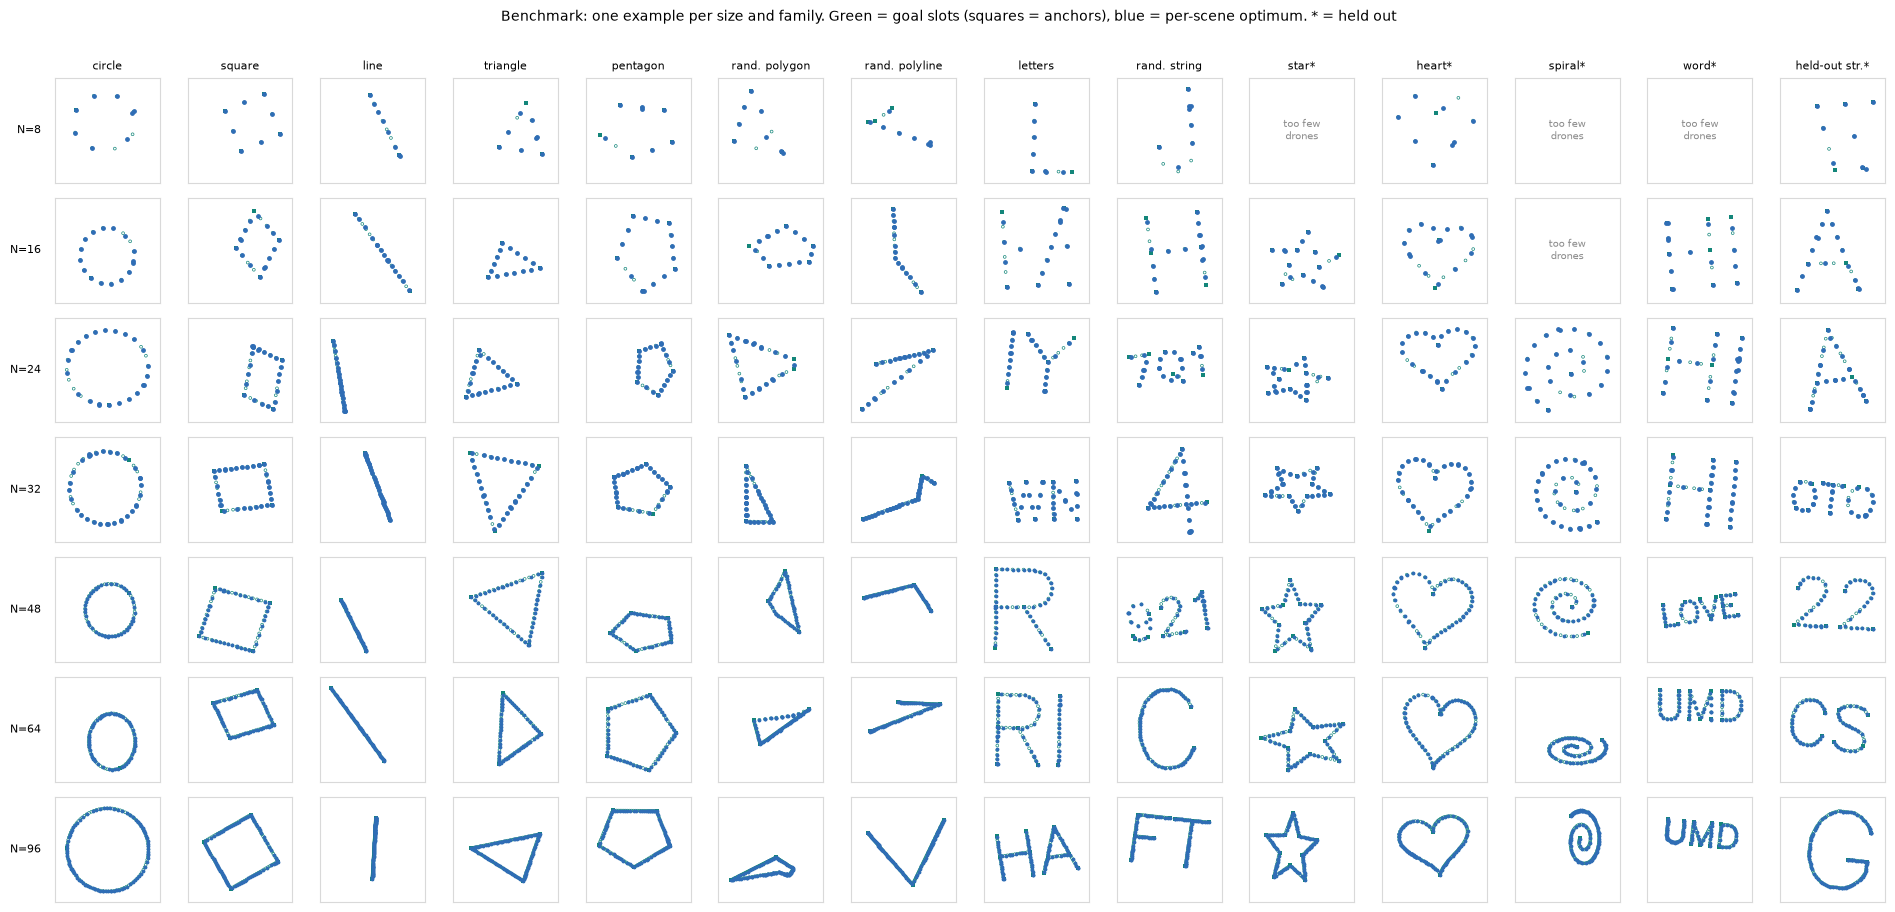

In [3]:
fig = viz.plot_benchmark_overview(FIGS / "phase2_v3_benchmark.png")
plt.show()

## 3. What one drone sees

The blue drone sees its 6 nearest drones (orange), its 8 nearest goal slots (green), and for each of those slots **how close the nearest other drone is** (small = taken, go elsewhere). Plus the scene's d_min and its own velocity: 39 numbers, whatever the swarm size.

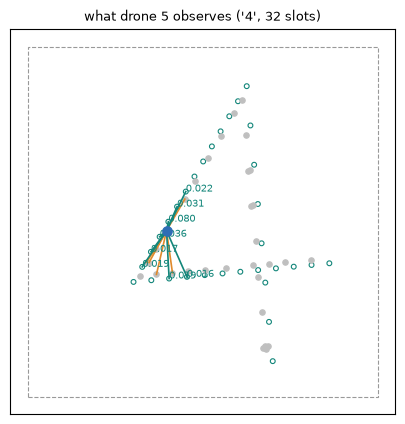

d_min for this scene: 0.0250   (goal labels: distance from that goal to the nearest other drone)


In [4]:
cell = load_cell(32, "train")
s = cell["family"].index("random_string")
pos, Q1 = cell["oracle_final"][s:s + 1] * 0.9, cell["goals"][s:s + 1]       # drones near (not on) the goals
i = 5
nb = knn_offsets(pos, pos, cfg.policy.k_neighbors, exclude_self=True)[0, i]
gidx = _knn_idx(pos, Q1, cfg.policy.m_targets, False)
occ = goal_occupancy(pos, Q1, gidx)[0, i]
p = pos[0, i]
fig, ax = plt.subplots(figsize=(5, 5))
viz._setup(ax, Q1[0], f"what drone 5 observes ('{cell['text'][s]}', 32 slots)")
ax.scatter(*pos[0].T, s=14, color="0.75", zorder=2)
for o in nb:
    ax.plot(*torch.stack([p, p + o]).T, color="#E08A2C", lw=1.2)
for j, o in enumerate(Q1[0, gidx[0, i]] - p):
    ax.plot(*torch.stack([p, p + o]).T, color="#13867A", lw=1.2)
    ax.annotate(f"{occ[j]:.3f}", (p + o).tolist(), fontsize=7, color="#13867A")
ax.scatter(*p, s=45, color="#2F6DB5", zorder=4)
plt.show()
print(f"d_min for this scene: {cell['d_min'][s]:.4f}   (goal labels: distance from that goal to the nearest other drone)")

## 4. Training

Each iteration: draw N in 8-96 → 32 random scenes with N slots → closed-loop rollout (observe → policy → `sim.step`) → loss (Chamfer over the last 20% of steps + collision + effort, plus the spacing term if the experiment turns it on; each scene divided by its spacing²) → backward through every step → clip → Adam. Rollouts grow 40 → 70 → 100 steps; the learning rate decays with a cosine schedule.

Every 250 iterations the benchmark (training shapes) is scored. **v3 model selection and early stopping use the mean slot error** (drone-to-own-slot distance in spacings, from one-to-one matching): the best checkpoint is kept, and training stops if it hasn't improved by 1% for 4 checks.

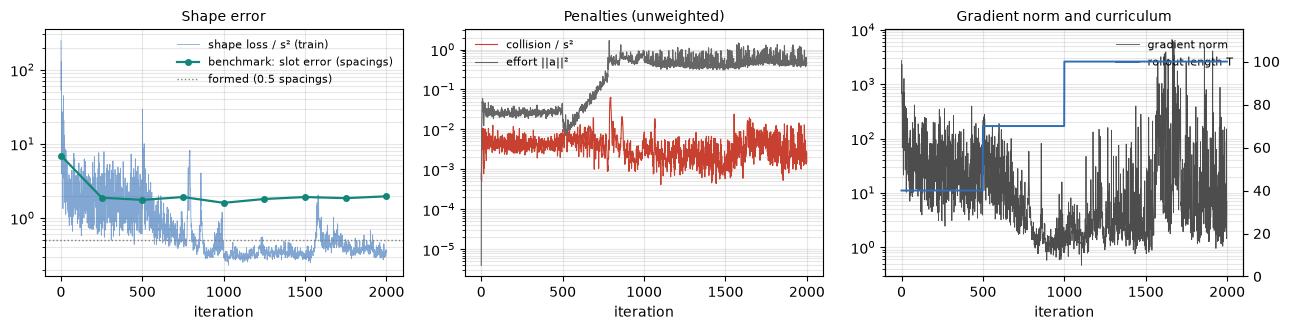

iteration 2000/3000   N=47   T=100   benchmark: slot error 1.959, filled 42% (it 2000)   26.2 min


early-stopped at iteration 2000; best checkpoint: iteration 1000, slot error 1.600, filled 42% -> results/models/phase2_v3_spacing.pt


In [5]:
def live(history):
    clear_output(wait=True)
    viz.plot_training(history)
    plt.show()
    tr, val = history["train"][-1], history["val"][-1]
    print(f"iteration {tr['it'] + 1}/{cfg.train.iters}   N={tr['n']}   T={tr['T']}   benchmark: slot error "
          f"{val['slot_error']:.3f}, filled {100 * val['filled']:.0f}% (it {val['it']})   {tr['time'] / 60:.1f} min")

if TRAIN:
    policy, history = train(cfg, run_dir=RUN, callback=live, callback_every=100)
    viz.plot_training(history, path=FIGS / f"{TAG}_training.png")
    plt.close()
else:
    history = json.loads((RUN / "history.json").read_text())
    display(Image(filename=FIGS / f"{TAG}_training.png"))

ckpt = torch.load(RUN / "best.pt", weights_only=False)
policy = SharedMLP.load(RUN / "best.pt").eval()
Path("results/models").mkdir(parents=True, exist_ok=True)
shutil.copy(RUN / "best.pt", f"results/models/{TAG}.pt")              # tracked by git (runs/ is not)
stop = history.get("stopped_at")
print(f"{'early-stopped at iteration ' + str(stop) if stop else 'ran all iterations'}; best checkpoint: iteration "
      f"{ckpt['it']}, slot error {ckpt['val_score']:.3f}, filled {100 * ckpt['val_filled']:.0f}% -> results/models/{TAG}.pt")

## 5. Results per swarm size

All at the last step (T = 100), means over the cell's scenes. Defined in `swarm/metrics.py`:
- **slots filled**: share of goal slots whose matched drone (one-to-one Hungarian matching) is within d_min. Split into **anchors** (ends, corners, junctions) and **fill** slots.
- **slot error**: mean matched drone-to-slot distance, in drone spacings.
- **steps to form**: first step after which the slot error stays below 0.5 spacings until the end (median over the scenes that formed; *formed* = share that did).
- **shared goals**: share of slots that are the nearest slot of 2+ drones (a pile-up that leaves a neighbor empty).
- **× opt**: Chamfer ÷ per-scene optimum (secondary in v3: with one slot per drone the optimum is ~0).

train    slots filled 42% (optimum 72%)   slot error 1.600 (optimum 1.195)   steps to form 64   formed 12%
heldout  slots filled 50% (optimum 76%)   slot error 1.183 (optimum 0.983)   steps to form 32   formed 15%
untrained policy: slots filled 4%, slot error 6.90

--- train shapes
   N  filled  anchor   fill   opt slot err   opt  form@  formed  shared  close  uneven   ×opt
   8     55%     39%    63%   85%     0.54  0.27     52     53%     20%    0.8   0.364    7.0
  16     51%     43%    53%   83%     0.69  0.38     84     22%     18%    1.5   0.439    4.5
  24     45%     55%    44%   77%     1.04  0.73     57      8%     18%    2.5   0.480    2.9
  32     38%     48%    37%   75%     1.39  0.77    nan      0%     19%    3.6   0.508    3.3
  48     40%     49%    39%   71%     1.73  1.12    nan      0%     19%    7.1   0.554    2.9
  64     36%     42%    36%   63%     2.48  1.59    nan      0%     18%   12.1   0.577    2.9
  96     33%     47%    32%   53%     3.33  3.51    nan    

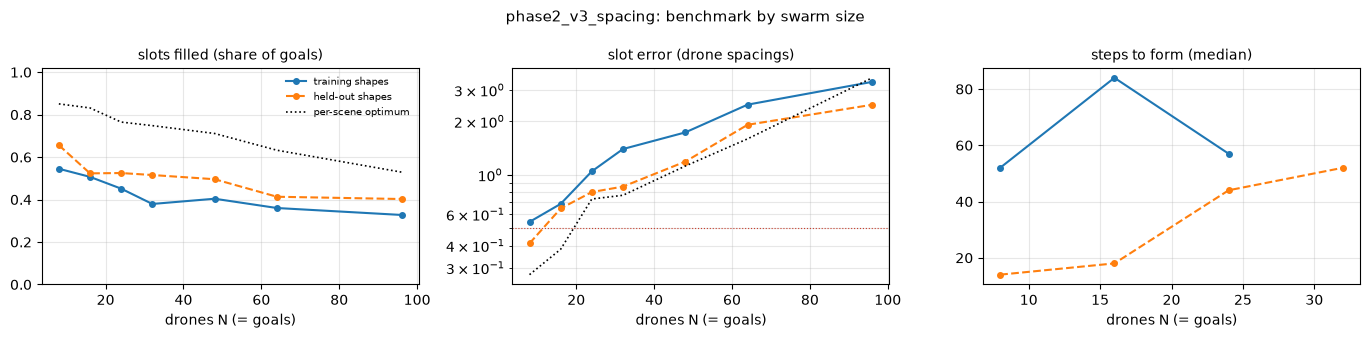

In [6]:
untrained = policy_from_config(cfg).eval()
rows = {sp: evaluate_benchmark(policy, cfg, sp, form=True) for sp in ("train", "heldout")}
rows0 = evaluate_benchmark(untrained, cfg, "train")
for sp in ("train", "heldout"):
    print(f"{sp:8s} slots filled {100 * overall(rows[sp], 'filled'):.0f}% (optimum {100 * overall(rows[sp], 'oracle_filled'):.0f}%)   "
          f"slot error {overall(rows[sp], 'slot_error'):.3f} (optimum {overall(rows[sp], 'oracle_slot_error'):.3f})   "
          f"steps to form {overall(rows[sp], 'steps_to_form'):.0f}   formed {100 * overall(rows[sp], 'formed'):.0f}%")
print(f"untrained policy: slots filled {100 * overall(rows0, 'filled'):.0f}%, slot error {overall(rows0, 'slot_error'):.2f}\n")
for sp in ("train", "heldout"):
    print(f"--- {sp} shapes")
    print(f"{'N':>4s}{'filled':>8s}{'anchor':>8s}{'fill':>7s}{'opt':>6s}{'slot err':>9s}{'opt':>6s}{'form@':>7s}{'formed':>8s}"
          f"{'shared':>8s}{'close':>7s}{'uneven':>8s}{'×opt':>7s}")
    for r in rows[sp]:
        print(f"{r['n']:4d}{100 * r['filled']:7.0f}%{100 * r['filled_anchor']:7.0f}%{100 * r['filled_fill']:6.0f}%"
              f"{100 * r['oracle_filled']:5.0f}%{r['slot_error']:9.2f}{r['oracle_slot_error']:6.2f}{r['steps_to_form']:7.0f}"
              f"{100 * r['formed']:7.0f}%{100 * r['shared_goals']:7.0f}%{r['close_pairs']:7.1f}{r['uniformity']:8.3f}{r['ratio']:7.1f}")
Path(f"results/{TAG}_scores.json").write_text(json.dumps(rows, indent=1))
fig = viz.plot_scores_by_n({"training shapes": rows["train"], "held-out shapes": rows["heldout"]},
                           FIGS / f"{TAG}_scores.png", title=f"{TAG}: benchmark by swarm size", oracle_rows=rows["train"])
plt.show()

## 6. Every size and shape: policy final positions (compare with the optimum figure in section 2)

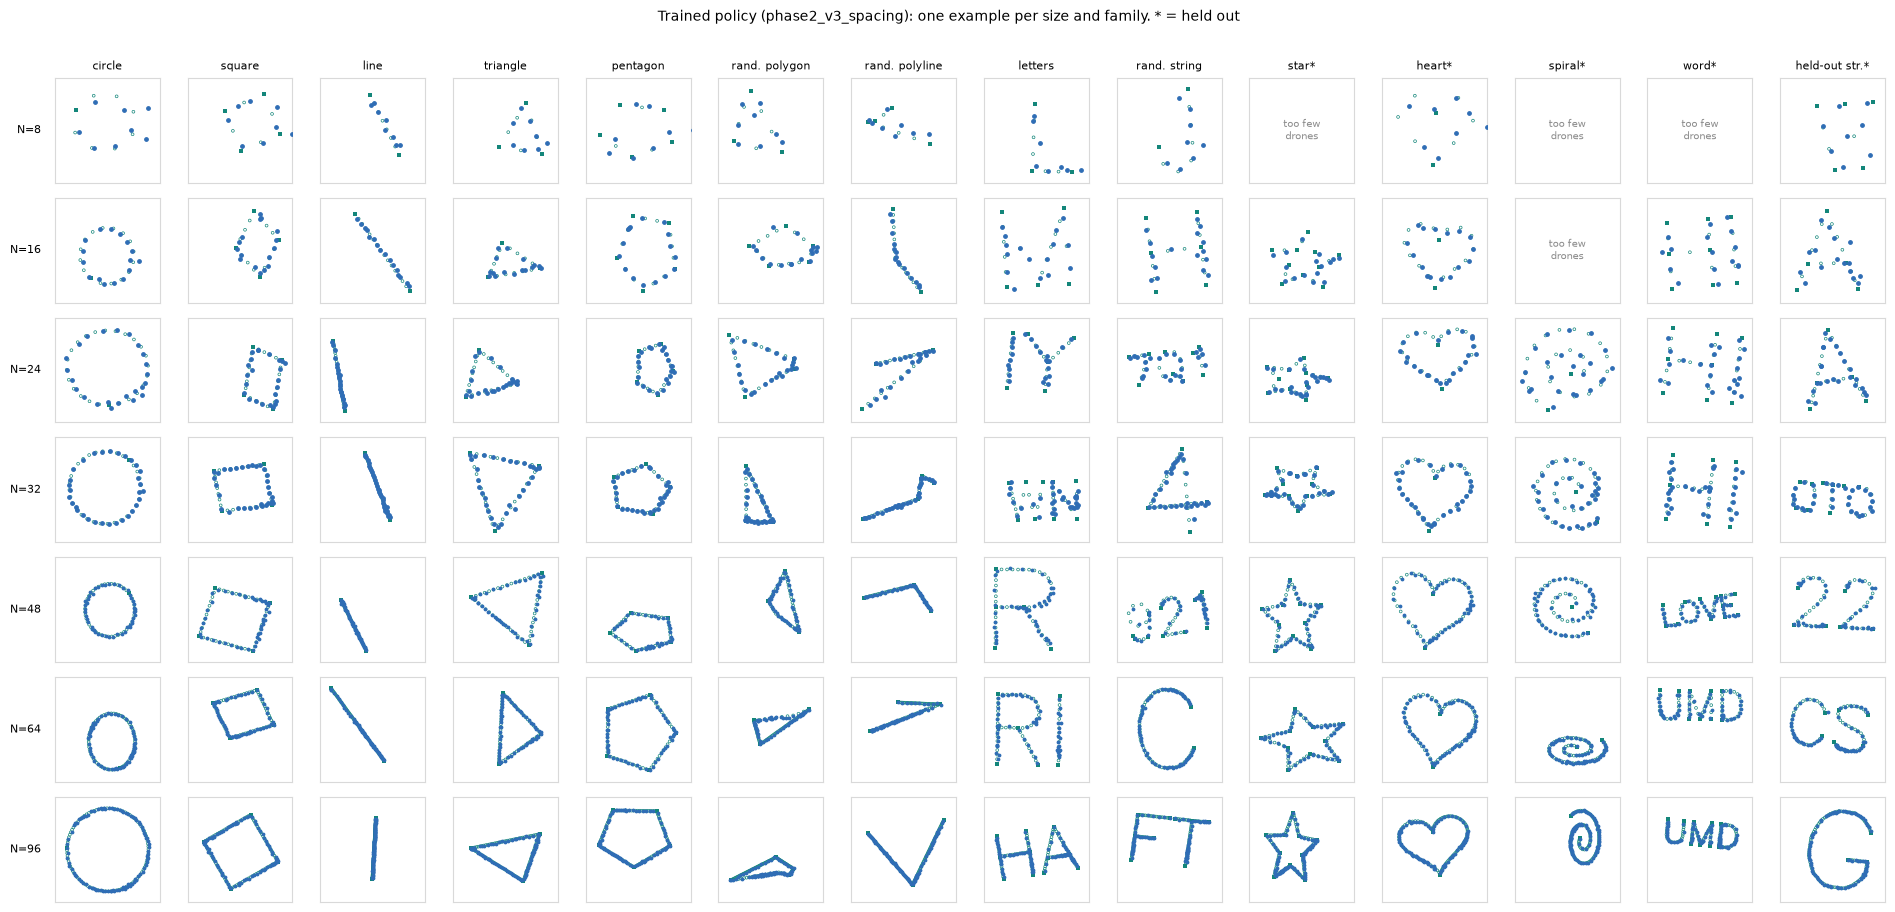

In [7]:
finals, evals = {}, {}
for n in BENCH_N:
    for sp in ("train", "heldout"):
        evals[(n, sp)] = evaluate_cell(policy, load_cell(n, sp), cfg)
        finals[(n, sp)] = evals[(n, sp)]["traj"][:, -1]
fig = viz.plot_benchmark_overview(FIGS / f"{TAG}_policy_overview.png", finals=finals,
                                  title=f"Trained policy ({TAG}): one example per size and family. * = held out")
plt.show()

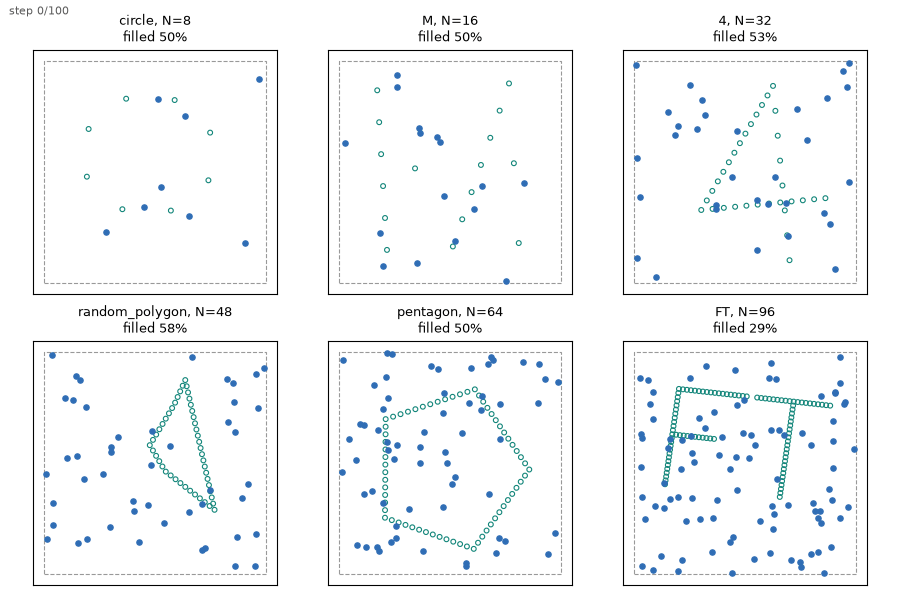

In [8]:
def pick(n, sp, fam, k=0):
    c = load_cell(n, sp); i = [j for j, f in enumerate(c["family"]) if f == fam][k]
    e = evals[(n, sp)]
    name = c["text"][i].replace("\n", " ") if c["text"][i] else fam
    return e["traj"][i], c["goals"][i], f"{name}, N={n}\nfilled {100 * e['filled'][i]:.0f}%"

picks = [(8, "train", "circle"), (16, "train", "letters"), (32, "train", "random_string"),
         (48, "train", "random_polygon"), (64, "train", "pentagon"), (96, "train", "random_string")]
trajs, goals, titles = zip(*[pick(*p) for p in picks])
gif = viz.save_gif_grid(trajs, goals, GIFS / f"{TAG}_cells.gif", titles=titles, cols=3, panel=3.0)
display(Image(filename=gif))

## 7. Held-out shapes, strings and words

None of these were in training. Each drone only sees nearby slots, so it does not need to know which shape or letter it is in.

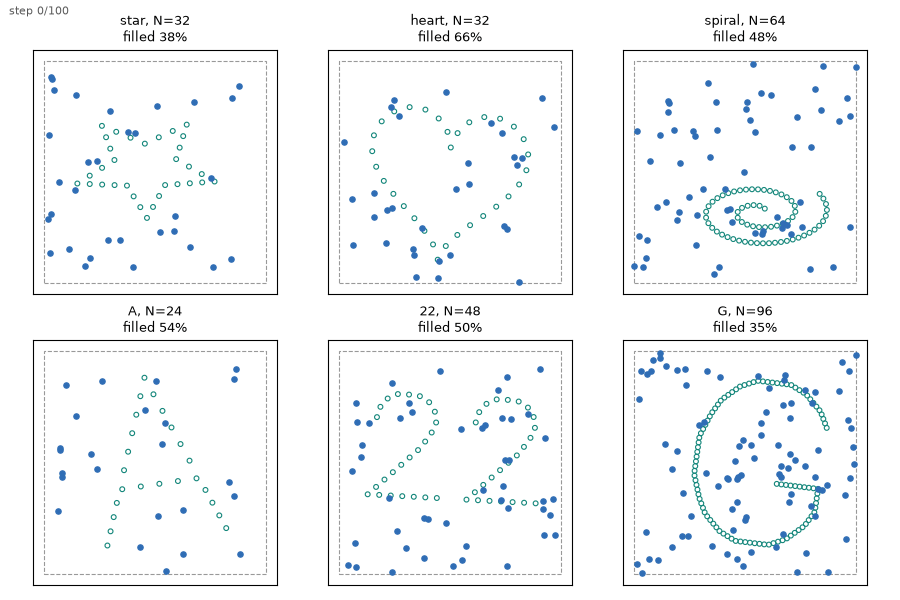

In [9]:
shapes = [pick(32, "heldout", "star"), pick(32, "heldout", "heart"), pick(64, "heldout", "spiral"),
          pick(24, "heldout", "heldout_string"), pick(48, "heldout", "heldout_string"), pick(96, "heldout", "heldout_string")]
trajs, goals, titles = zip(*shapes)
gif = viz.save_gif_grid(trajs, goals, GIFS / f"{TAG}_heldout.gif", titles=titles, cols=3, panel=3.0)
display(Image(filename=gif))

word         N  filled slot err  form@
HI          16     50%     0.90    nan
UMD         32     72%     0.63    nan
FIRE        48     52%     0.66    nan
LOVE        48     65%     0.70    nan
MARRY ME    96     33%     2.14    nan


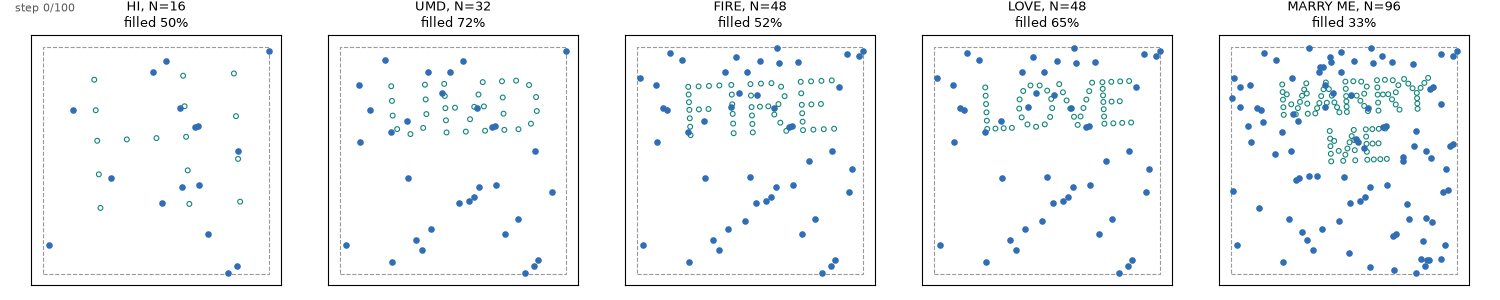

In [10]:
def run_text(text, n, seed=0, steps=None):
    sc = text_scene(text, n, seed)
    e = evaluate_cell(policy, sc, cfg, steps=steps, form=True)
    return e, sc

word_runs = [("HI", 16), ("UMD", 32), ("FIRE", 48), ("LOVE", 48), ("MARRY\nME", 96)]
trajs, goals, titles = [], [], []
print(f"{'word':10s}{'N':>4s}{'filled':>8s}{'slot err':>9s}{'form@':>7s}")
for text, n in word_runs:
    e, sc = run_text(text, n)
    name = text.replace("\n", " ")
    print(f"{name:10s}{n:4d}{100 * e['filled'][0]:7.0f}%{e['slot_error'][0]:9.2f}{e['steps_to_form'][0]:7.0f}")
    trajs.append(e["traj"][0]); goals.append(sc["goals"][0]); titles.append(f"{name}, N={n}\nfilled {100 * e['filled'][0]:.0f}%")
gif = viz.save_gif_grid(trajs, goals, GIFS / f"{TAG}_words.gif", titles=titles, cols=5, panel=3.0)
display(Image(filename=gif))

## 8. Beyond the training range: 128 drones

Training never used more than 96 drones. 150 steps here, since bigger swarms travel farther to spread out.

MARRY ME     N=128  filled 30%  slot error 2.83  steps to form nan
HELLO WORLD  N=128  filled 39%  slot error 1.50  steps to form nan


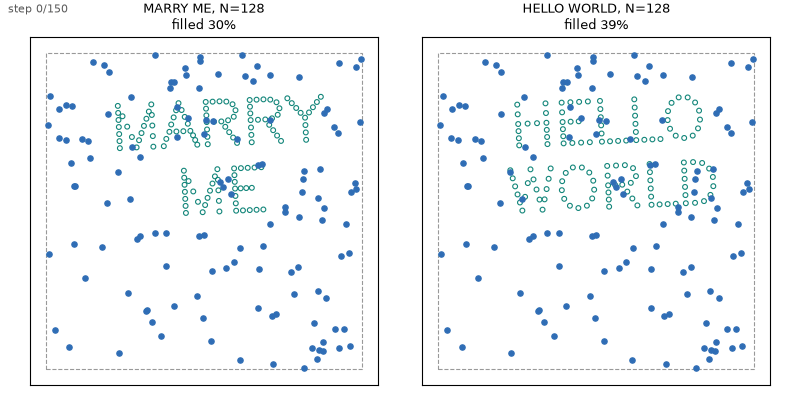

In [11]:
trajs, goals, titles = [], [], []
for text in ["MARRY\nME", "HELLO\nWORLD"]:
    e, sc = run_text(text, 128, steps=150)
    name = text.replace("\n", " ")
    print(f"{name:12s} N=128  filled {100 * e['filled'][0]:.0f}%  slot error {e['slot_error'][0]:.2f}  "
          f"steps to form {e['steps_to_form'][0]:.0f}")
    trajs.append(e["traj"][0]); goals.append(sc["goals"][0]); titles.append(f"{name}, N=128\nfilled {100 * e['filled'][0]:.0f}%")
gif = viz.save_gif_grid(trajs, goals, GIFS / f"{TAG}_demo128.gif", titles=titles, cols=2, panel=4.0)
display(Image(filename=gif))

## 9. Policy vs the Phase 1 fixed plan

The plan is optimized once for start 0 and replayed from 15 other starts; the policy just runs.

In [12]:
c = load_cell(32, "train"); i = c["family"].index("circle")
Qc, dm = c["goals"][i:i + 1], c["d_min"][i:i + 1]
starts = torch.rand(16, 32, 2, generator=torch.Generator().manual_seed(0)) - 0.5
plan = optimize_plan(starts[:1], Qc, cfg, d_min=dm, w_collision=cfg.loss.w_collision)["accs"]
v0 = torch.zeros(1, 32, 2)
from swarm.metrics import slot_metrics
with torch.no_grad():
    plan_f = [slot_metrics(rollout(s[None], v0, plan, cfg)[:, -1], Qc, dm)["filled"].item() for s in starts]
    pol_f = [slot_metrics(rollout_closed_loop(s[None], v0, Qc, dm, policy.act, cfg)[0][:, -1], Qc, dm)["filled"].item()
             for s in starts]
print(f"{'slots filled':30s}{'fixed plan':>12s}{'policy':>10s}")
print(f"{'start the plan was made for':30s}{100 * plan_f[0]:11.0f}%{100 * pol_f[0]:9.0f}%")
print(f"{'15 new starts (mean)':30s}{100 * np.mean(plan_f[1:]):11.0f}%{100 * np.mean(pol_f[1:]):9.0f}%")

slots filled                    fixed plan    policy
start the plan was made for            72%       78%
15 new starts (mean)                    3%       50%
